In [ ]:
# ============================================================
# 05_platform_clustering.ipynb — 환경 설정 (config.py 자동 로드)
# ============================================================
import sys
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import silhouette_score
import warnings; warnings.filterwarnings('ignore')

# 프로젝트 루트를 sys.path에 추가 (실행 위치 무관)
for _p in [Path.cwd(), Path.cwd().parent]:
    if (_p / 'config.py').exists():
        sys.path.insert(0, str(_p))
        break

from config import *  # 모든 상수·경로·KPI·시각화 설정·헬퍼 함수 일괄 적용
# ↑ N_CLUSTERS(4), CLUSTER_NAMES, CLUSTER_COLORS, KPI_REVPAR_ACTIVE_MEDIAN 포함

# ── 자치구 집계 데이터 로드 (04_platform_eda 출력물)
try:
    district_agg = load_district_agg()
    print(f"✅ 자치구 집계 데이터 로드: {district_agg.shape}")
except FileNotFoundError:
    # 04_platform_eda가 아직 실행되지 않은 경우 — 직접 생성
    df = load_features()
    mask_ao = (df['refined_status'] == 'Active') & (df['operation_status'] == 'Operating')
    district_agg = df.groupby('district').agg(
        total_listings=('ttm_revpar', 'count'),
        ao_count=('is_active_operating', 'sum'),
        median_revpar_ao=('ttm_revpar',
            lambda x: x[df.loc[x.index, 'is_active_operating'] == 1].median()
            if (df.loc[x.index, 'is_active_operating'] == 1).any() else 0),
        dormant_count=('refined_status', lambda x: x.isin(['Dormant', 'Ghost']).sum()),
        superhost_rate=('superhost', 'mean'),
        median_pop=('ttm_pop', 'median'),
    ).reset_index()
    district_agg['dormant_ratio'] = (
        district_agg['dormant_count'] / district_agg['total_listings']
    )
    district_agg['supply_share'] = (
        district_agg['total_listings'] / district_agg['total_listings'].sum()
    )
    district_agg.to_csv(CSV_DISTRICT_AGG, index=False, encoding='utf-8-sig')
    print(f"✅ 집계 데이터 생성: {district_agg.shape}")

print(f"   클러스터 수(k): {N_CLUSTERS}")

# 🗺️ 자치구 K-Means 클러스터링

**목적:** 25개 자치구를 RevPAR 성과 특성에 따라 4개 군집으로 분류합니다.

**클러스터링 피처:** median_revpar_ao, total_listings, dormant_ratio, superhost_rate, supply_share

**예상 군집:** 프리미엄 관광거점 / 성장형 주거상권 / 중가 균형시장 / 가격민감 외곽형

## 1️⃣ 최적 k 결정 (Elbow + Silhouette)

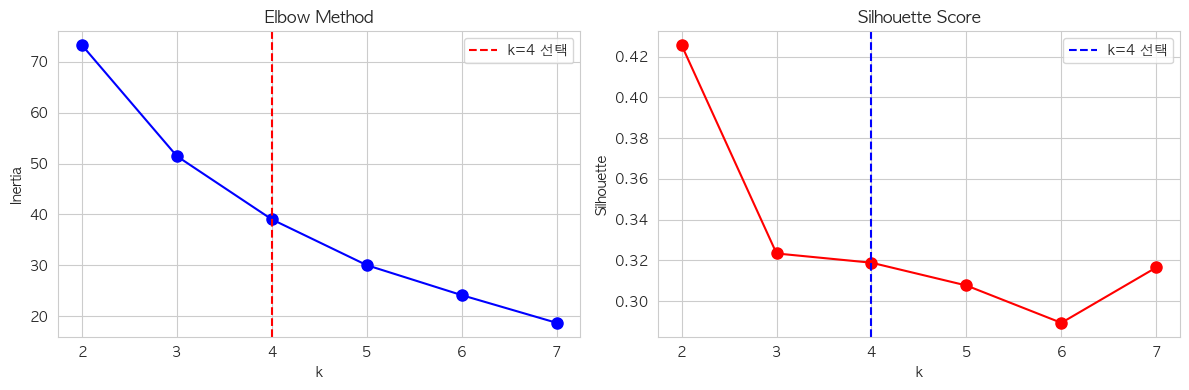

k=4 Silhouette: 0.3188


In [3]:
cluster_features = ["median_revpar_ao","total_listings","dormant_ratio","superhost_rate","supply_share"]
X_cluster = district_agg[cluster_features].fillna(0)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

inertias, silhouettes = [], []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(2,8), inertias, "bo-", markersize=8)
axes[0].axvline(N_CLUSTERS, color="red", linestyle="--", label=f"k={N_CLUSTERS} 선택")
axes[0].set_title("Elbow Method", fontsize=12, fontweight="bold"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia"); axes[0].legend()
axes[1].plot(range(2,8), silhouettes, "ro-", markersize=8)
axes[1].axvline(N_CLUSTERS, color="blue", linestyle="--", label=f"k={N_CLUSTERS} 선택")
axes[1].set_title("Silhouette Score", fontsize=12, fontweight="bold"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette"); axes[1].legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR/"fig_05_elbow_silhouette.png", dpi=100, bbox_inches="tight"); plt.show()
print(f"k={N_CLUSTERS} Silhouette: {silhouettes[N_CLUSTERS-2]:.4f}")

## 2️⃣ K-Means 클러스터링 (k=4)

In [4]:
km_final = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_SEED, n_init=10)
district_agg["cluster"] = km_final.fit_predict(X_scaled)

# RevPAR 기준으로 클러스터 순위 부여
cluster_revpar = district_agg.groupby("cluster")["median_revpar_ao"].median().sort_values(ascending=False)
rank_map = {old: new for new, old in enumerate(cluster_revpar.index)}
district_agg["cluster_rank"] = district_agg["cluster"].map(rank_map)

cluster_names = {0:"프리미엄 관광거점", 1:"성장형 주거상권", 2:"중가 균형시장", 3:"가격민감 외곽형"}
district_agg["cluster_name"] = district_agg["cluster_rank"].map(cluster_names)

print("클러스터별 자치구:")
for cid, name in cluster_names.items():
    members = district_agg[district_agg["cluster_rank"]==cid]["district"].tolist()
    revpar = district_agg[district_agg["cluster_rank"]==cid]["median_revpar_ao"].median()
    print(f"\n  [{name}] RevPAR 중위값: ₩{revpar:,.0f}")
    print(f"       {', '.join(members)}")

클러스터별 자치구:

  [프리미엄 관광거점] RevPAR 중위값: ₩63,366
       Mapo-gu

  [성장형 주거상권] RevPAR 중위값: ₩53,052
       Gangnam-gu, Jongno-gu, Jung-gu, Seocho-gu, Yongsan-gu

  [중가 균형시장] RevPAR 중위값: ₩35,881
       Dobong-gu, Eunpyeong-gu, Gangbuk-gu, Gangdong-gu, Gangseo-gu, Gwangjin-gu, Jungnang-gu, Nowon-gu, Seongbuk-gu, Seongdong-gu, Songpa-gu, Yangcheon-gu, Yeongdeungpo-gu

  [가격민감 외곽형] RevPAR 중위값: ₩26,413
       Dongdaemun-gu, Dongjak-gu, Geumcheon-gu, Guro-gu, Gwanak-gu, Seodaemun-gu


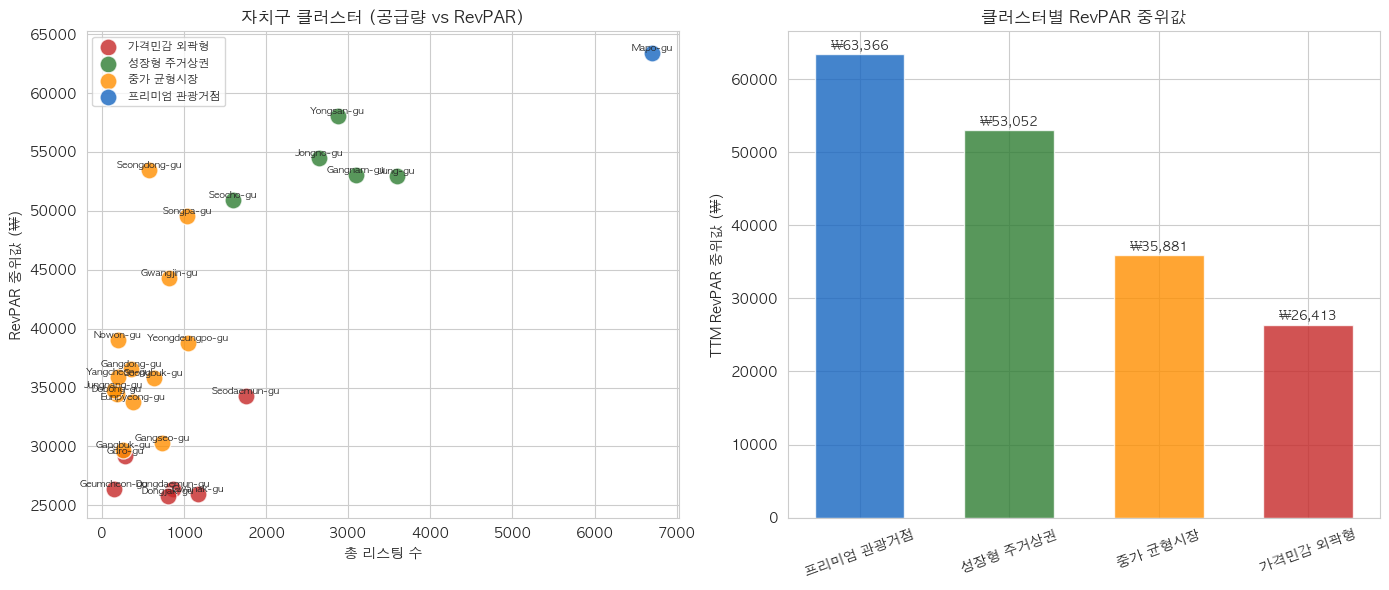

In [5]:
CLUSTER_COLORS = {"프리미엄 관광거점":"#1565C0","성장형 주거상권":"#2E7D32","중가 균형시장":"#FF8F00","가격민감 외곽형":"#C62828"}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name, group in district_agg.groupby("cluster_name"):
    axes[0].scatter(group["total_listings"], group["median_revpar_ao"], s=150, label=name, color=CLUSTER_COLORS[name], alpha=0.8, edgecolors="white")
    for _, row in group.iterrows():
        axes[0].annotate(row["district"], (row["total_listings"], row["median_revpar_ao"]), fontsize=7, ha="center", va="bottom")
axes[0].set_title("자치구 클러스터 (공급량 vs RevPAR)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("총 리스팅 수"); axes[0].set_ylabel("RevPAR 중위값 (₩)"); axes[0].legend(fontsize=8)

for i, name in cluster_names.items():
    rev = district_agg[district_agg["cluster_rank"]==i]["median_revpar_ao"].median()
    axes[1].bar(i, rev, color=CLUSTER_COLORS[name], alpha=0.8, width=0.6)
    axes[1].text(i, rev+300, f"₩{rev:,.0f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[1].set_title("클러스터별 RevPAR 중위값", fontsize=12, fontweight="bold")
axes[1].set_ylabel("TTM RevPAR 중위값 (₩)")
axes[1].set_xticks(range(4)); axes[1].set_xticklabels([cluster_names[i] for i in range(4)], rotation=20)
plt.tight_layout()
plt.savefig(REPORTS_DIR/"fig_05_cluster_scatter.png", dpi=100, bbox_inches="tight"); plt.show()

## 3️⃣ 클러스터별 특성 프로파일링

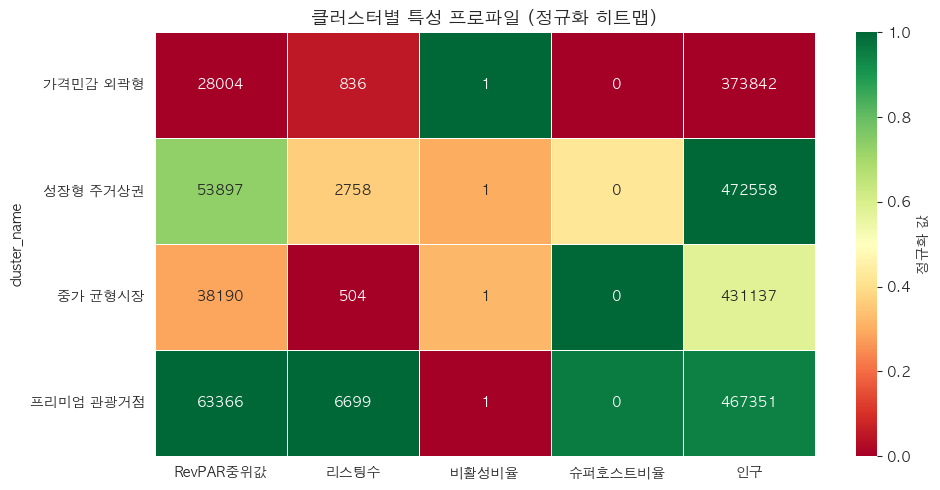

In [6]:
profile_cols = ["median_revpar_ao","total_listings","dormant_ratio","superhost_rate","median_pop"]
profile_labels = ["RevPAR중위값","리스팅수","비활성비율","슈퍼호스트비율","인구"]
cluster_profile = district_agg.groupby("cluster_name")[profile_cols].mean()

mms = MinMaxScaler()
profile_norm = pd.DataFrame(mms.fit_transform(cluster_profile), index=cluster_profile.index, columns=profile_labels)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(profile_norm, annot=cluster_profile.values.round(0), fmt=".0f", cmap="RdYlGn", ax=ax, linewidths=0.5, cbar_kws={"label":"정규화 값"})
ax.set_title("클러스터별 특성 프로파일 (정규화 히트맵)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORTS_DIR/"fig_05_cluster_profile_heatmap.png", dpi=100, bbox_inches="tight"); plt.show()

In [7]:
district_agg.to_csv(PROCESSED_DIR/"district_clustered.csv", index=False, encoding="utf-8-sig")
print("✅ 클러스터 결과 저장: data/processed/district_clustered.csv")
print("\n📋 클러스터 요약:")
print(district_agg.groupby("cluster_name").agg(자치구수=("district","count"), RevPAR중위=("median_revpar_ao","median"), 비활성비율=("dormant_ratio","mean")).round(3).to_string())

✅ 클러스터 결과 저장: data/processed/district_clustered.csv

📋 클러스터 요약:
              자치구수  RevPAR중위  비활성비율
cluster_name                       
가격민감 외곽형         6   26413.2  0.633
성장형 주거상권         5   53051.6  0.545
중가 균형시장         13   35881.1  0.547
프리미엄 관광거점        1   63365.5  0.507


## 4️⃣ 클러스터별 추가인원요금 정책 효과 분석

**분석 목적:** 클러스터(cluster_name)별로 추가요금이 있는 숙소와 없는 숙소의 RevPAR 중위값을 비교한다.

**분석 대상:** Active + Operating 서브셋 (n=14,399)  
**검정 방법:** Mann-Whitney U 검정 (비모수, 양측)  
**유의수준:** p < 0.05 (Bonferroni 보정 미적용 — 클러스터 간 독립 비교)

In [ ]:
# ── 데이터 준비: listing 단위 데이터에 cluster_name 병합
from pathlib import Path
from scipy import stats
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

_BASE = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
_FEATURES  = _BASE / "data" / "processed" / "seoul_airbnb_features.csv"
_CLUSTERED = _BASE / "data" / "processed" / "district_clustered.csv"
_REPORTS   = _BASE / "reports"

df_raw   = pd.read_csv(_FEATURES)
df_clust = pd.read_csv(_CLUSTERED)[["district", "cluster_name"]]

ao = df_raw[
    (df_raw["refined_status"] == "Active") &
    (df_raw["operation_status"] == "Operating")
].merge(df_clust, on="district", how="left")

CLUSTER_ORDER  = ["프리미엄 관광거점", "성장형 주거상권", "중가 균형시장", "가격민감 외곽형"]
CLUSTER_COLORS = {"프리미엄 관광거점": "#1565C0", "성장형 주거상권": "#2E7D32",
                  "중가 균형시장": "#FF8F00", "가격민감 외곽형": "#C62828"}

# ── 클러스터별 요약 통계 + Mann-Whitney U 검정
rows = []
for cl in CLUSTER_ORDER:
    sub     = ao[ao["cluster_name"] == cl]
    has_fee = sub.loc[sub["extra_guest_fee_policy"] == 1, "ttm_revpar"]
    no_fee  = sub.loc[sub["extra_guest_fee_policy"] == 0, "ttm_revpar"]
    stat, p = stats.mannwhitneyu(has_fee, no_fee, alternative="two-sided")
    diff    = has_fee.median() - no_fee.median()
    rows.append({
        "클러스터":        cl,
        "전체(n)":         len(sub),
        "추가요금있음(n)":  len(has_fee),
        "추가요금없음(n)":  len(no_fee),
        "도입률(%)":       round(len(has_fee) / len(sub) * 100, 1),
        "RevPAR_있음":     round(has_fee.median(), 0),
        "RevPAR_없음":     round(no_fee.median(), 0),
        "차이(₩)":         round(diff, 0),
        "비율":            round(has_fee.median() / no_fee.median(), 3),
        "p-value":         round(p, 4),
        "유의성":          "***" if p < 0.001 else ("*" if p < 0.05 else "ns"),
    })

summary = pd.DataFrame(rows)
print("=== 클러스터별 추가요금 정책 효과 요약 (Active+Operating, n=14,399) ===")
print(summary.to_string(index=False))


In [ ]:
# ── 시각화 1: 클러스터별 추가요금 유무 RevPAR 비교 (grouped bar + 차이 표시)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ① Grouped bar: 클러스터별 RevPAR 비교
x      = np.arange(len(CLUSTER_ORDER))
width  = 0.35
for ax in axes[:1]:
    bars_no  = ax.bar(x - width/2, summary["RevPAR_없음"], width,
                      label="추가요금 없음", color="#90CAF9", edgecolor="white", linewidth=0.8)
    bars_yes = ax.bar(x + width/2, summary["RevPAR_있음"], width,
                      label="추가요금 있음", color="#EF5350", edgecolor="white", linewidth=0.8, alpha=0.85)
    # 값 레이블
    for bar in bars_no:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 600,
                f"₩{bar.get_height()/1000:.0f}K", ha="center", va="bottom", fontsize=8.5, color="#1565C0", fontweight="bold")
    for bar in bars_yes:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 600,
                f"₩{bar.get_height()/1000:.0f}K", ha="center", va="bottom", fontsize=8.5, color="#B71C1C", fontweight="bold")
    # 유의성 표시
    for i, row in summary.iterrows():
        sig_y = max(row["RevPAR_없음"], row["RevPAR_있음"]) + 3500
        ax.text(i, sig_y, row["유의성"], ha="center", fontsize=11, color="black")
    ax.set_xticks(x)
    ax.set_xticklabels(CLUSTER_ORDER, fontsize=10)
    ax.set_ylabel("TTM RevPAR 중위값 (₩)", fontsize=11)
    ax.set_title("클러스터별 추가요금 정책 유무 RevPAR 비교", fontsize=12, fontweight="bold")
    ax.legend(fontsize=10)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"₩{v/1000:.0f}K"))

# ② 차이(₩) 수평 막대 + 도입률 이중 표시
ax2 = axes[1]
colors_bar = [CLUSTER_COLORS[c] for c in CLUSTER_ORDER]
bars = ax2.barh(CLUSTER_ORDER, summary["차이(₩)"], color=colors_bar, alpha=0.85, edgecolor="white")
ax2.axvline(0, color="black", linewidth=1.2, linestyle="--")
for i, (bar, row) in enumerate(zip(bars, summary.itertuples())):
    sign  = "▼" if row._8 < 0 else "▲"   # 차이(₩) 컬럼 index
    label = f"{sign} ₩{abs(row._8)/1000:.1f}K  (도입률 {row._6}%)"  # 도입률(%) index
    x_pos = row._8 - 1200 if row._8 < 0 else row._8 + 400
    ha    = "right" if row._8 < 0 else "left"
    ax2.text(x_pos, i, label, va="center", ha=ha, fontsize=9.5, fontweight="bold", color="white" if row._8 < 0 else "black")
ax2.set_xlabel("RevPAR 차이 (추가요금 있음 − 없음, ₩)", fontsize=11)
ax2.set_title("클러스터별 RevPAR 차이 및 도입률", fontsize=12, fontweight="bold")
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"₩{v/1000:.0f}K"))

plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig_05_extra_fee_by_cluster.png", dpi=100, bbox_inches="tight")
plt.show()


In [ ]:
# ── 시각화 2: 클러스터별 자치구 단위 RevPAR 차이 히트맵
dist_rows = []
for cl in CLUSTER_ORDER:
    sub_ao = ao[ao["cluster_name"] == cl]
    for dist, grp in sub_ao.groupby("district"):
        has = grp.loc[grp["extra_guest_fee_policy"] == 1, "ttm_revpar"]
        no  = grp.loc[grp["extra_guest_fee_policy"] == 0, "ttm_revpar"]
        if len(has) < 3:           # 표본 너무 작으면 제외
            continue
        diff = has.median() - no.median()
        dist_rows.append({
            "cluster_name": cl,
            "district":     dist,
            "n_fee":        len(has),
            "fee_pct":      round(len(has) / len(grp) * 100, 1),
            "revpar_yes":   round(has.median(), 0),
            "revpar_no":    round(no.median(), 0),
            "diff":         round(diff, 0),
        })

dist_df = pd.DataFrame(dist_rows).sort_values(["cluster_name", "diff"], ascending=[True, False])

fig, ax = plt.subplots(figsize=(14, 7))
pivot = dist_df.pivot(index="district", columns="cluster_name", values="diff")
# 클러스터 순서 정렬
pivot = pivot[CLUSTER_ORDER]

sns.heatmap(
    pivot, annot=True, fmt=".0f", cmap="RdYlGn",
    center=0, linewidths=0.6, linecolor="#cccccc",
    ax=ax, cbar_kws={"label": "RevPAR 차이 (₩)"},
    annot_kws={"size": 9},
)
ax.set_title("자치구 × 클러스터별 추가요금 정책 RevPAR 차이 (₩)\n(추가요금 있음 − 없음, 양수=긍정 효과)", fontsize=12, fontweight="bold")
ax.set_xlabel("클러스터", fontsize=11)
ax.set_ylabel("자치구", fontsize=11)
ax.tick_params(axis="x", rotation=15)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig_05_extra_fee_district_heatmap.png", dpi=100, bbox_inches="tight")
plt.show()


In [ ]:
# ── 인사이트 출력
print("=" * 65)
print("  클러스터별 추가요금 정책 효과 — 핵심 인사이트")
print("=" * 65)

for _, row in summary.iterrows():
    direction = "▼ 부정" if row["차이(₩)"] < 0 else "▲ 긍정"
    print(f"\n[{row['클러스터']}]  n={row['전체(n)']:,}  도입률={row['도입률(%)']}%  p={row['p-value']} {row['유의성']}")
    print(f"  추가요금 있음: ₩{row['RevPAR_있음']:,.0f}  |  없음: ₩{row['RevPAR_없음']:,.0f}")
    print(f"  → {direction}  차이: ₩{row['차이(₩)']:+,.0f}  (비율 {row['비율']:.3f}×)")

print("""
─────────────────────────────────────────────────────────────
[종합 해석]
① 모든 클러스터에서 추가요금 정책 도입 숙소의 RevPAR가
   통계적으로 유의미하게 낮음 (p < 0.001 / 0.001).

② 부정 효과는 클러스터 수익 수준이 높을수록 더 큼:
   프리미엄(-₩27.3K) > 성장형(-₩15.8K) > 중가(-₩6.8K) > 외곽(-₩4.5K)

③ 자기선택 편향(self-selection bias) 주의:
   추가요금 도입 숙소 자체가 규모가 크거나 비인기 지역일 가능성
   → 규모(bedrooms_group)·방 유형(room_type) 통제 후 재검증 필요.

④ 실전 권고:
   - 프리미엄·성장형: 추가요금 도입 효과 없음 — 기본가 구조 재설계 권장
   - 중가·외곽: 대형 숙소(8인+)에 한해 소규모 테스트 후 적용 판단
─────────────────────────────────────────────────────────────
""")
